# **Machine Learning: value and wage Prediction**

1. **Data preprocessing**

Import of librieries:

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import MultiTaskLasso, MultiTaskElasticNet
from sklearn.model_selection import GridSearchCV
import seaborn as sns
from sklearn.metrics import r2_score

Import of dataset, show of the shape and some EDA before the processing of the dataset. IN particular two histogram of the value and wage and their frequency in the dataset, then a graph to see the relation between the position of a player and his value

INizial shape: (17779, 64)


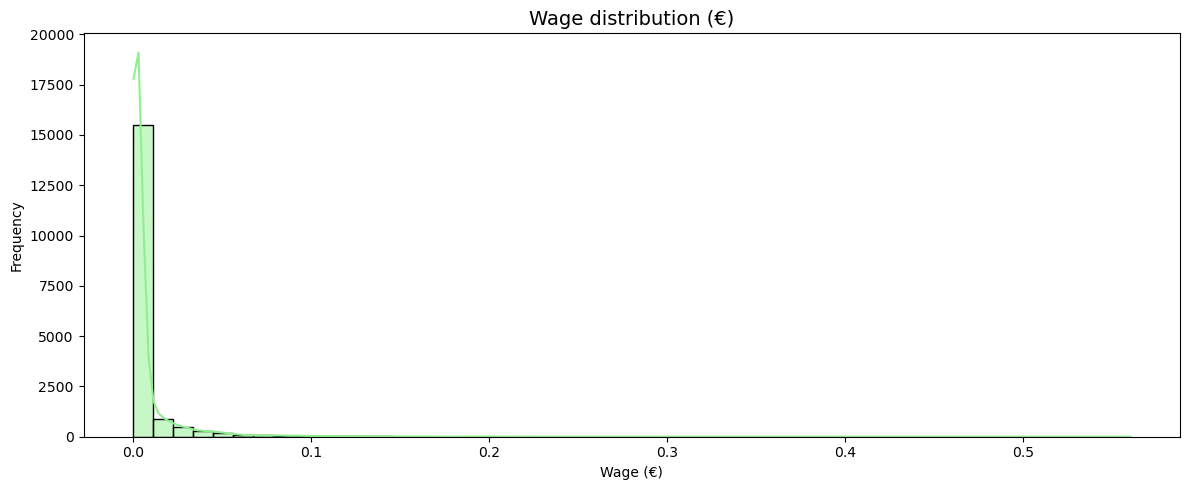

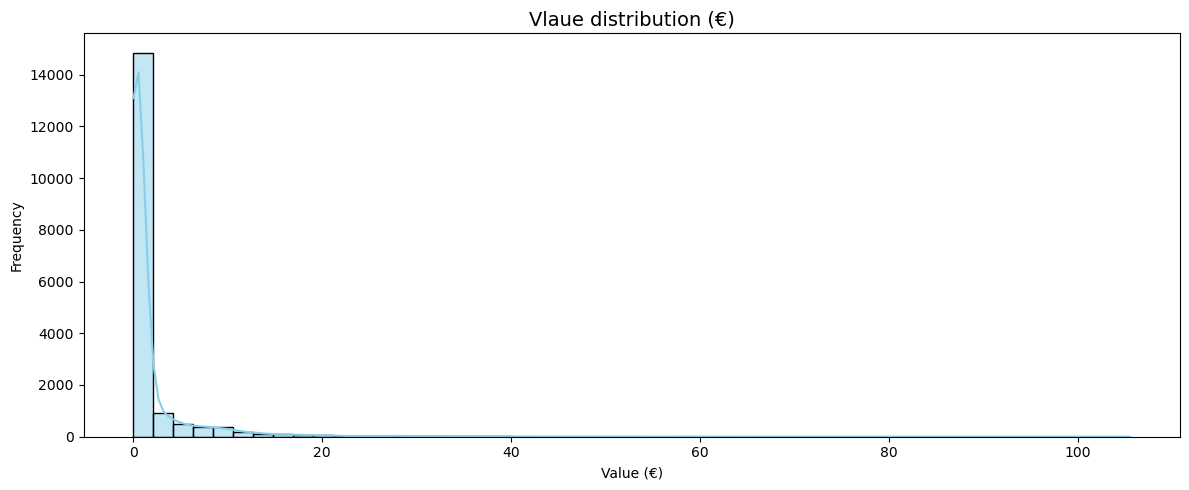

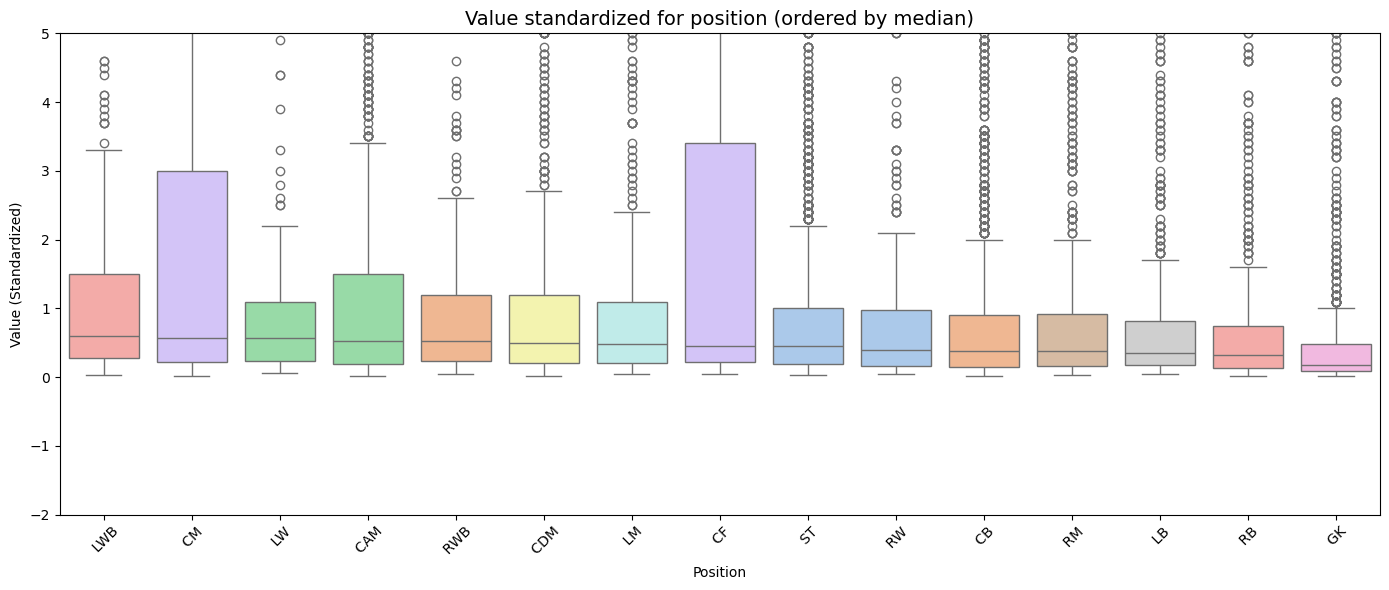

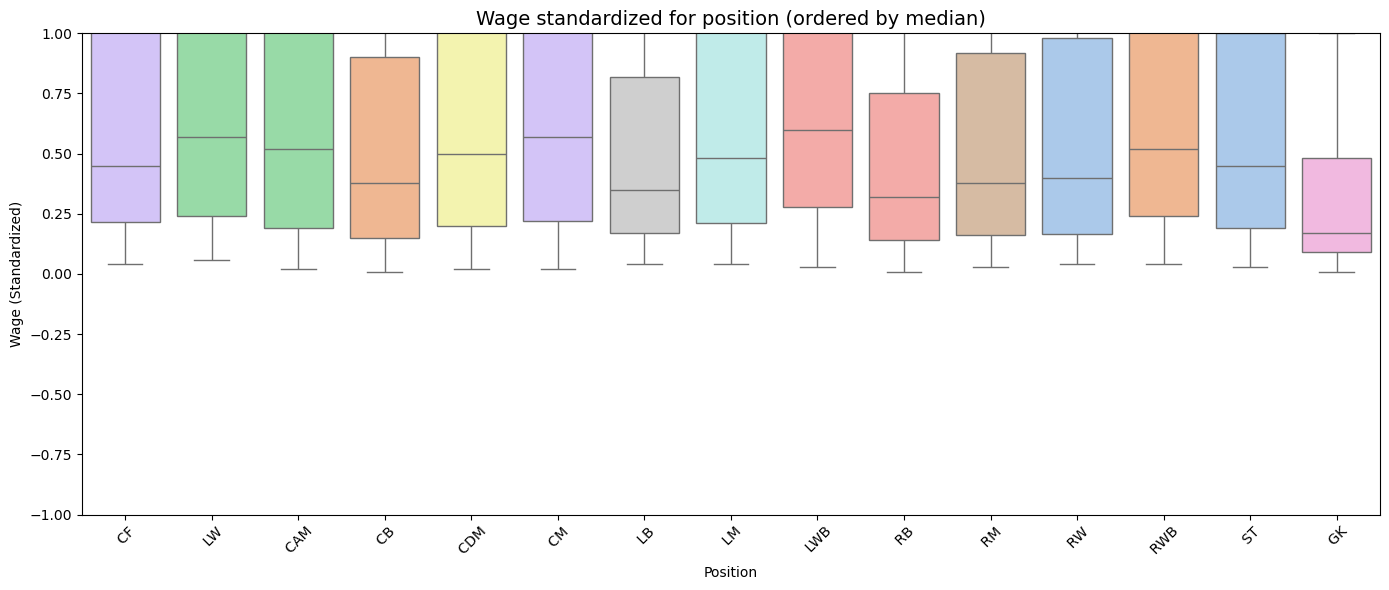

In [9]:

df = pd.read_csv("player_list.csv")
print("INizial shape:", df.shape)
#Wage
plt.figure(figsize=(12, 5))
sns.histplot(df['Wage'], bins=50, kde=True, color='lightgreen')
plt.title('Wage distribution (€)', fontsize=14)
plt.xlabel('Wage (€)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()
#Value
plt.figure(figsize=(12, 5))
sns.histplot(df['Value'], bins=50, kde=True, color='skyblue')
plt.title('Vlaue distribution (€)', fontsize=14)
plt.xlabel('Value (€)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

#boxplot to compare value and the position
order = df.groupby("Position")["Value"].median().sort_values(ascending=False).index
plt.figure(figsize=(14, 6))
sns.boxplot(x='Position', y='Value', data=df, order=order, hue='Position', palette='pastel', legend=False)
plt.title('Value standardized for position (ordered by median)', fontsize=14)
plt.xlabel('Position')
plt.ylabel('Value (Standardized)')
plt.ylim(-2, 5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#boxplot to compare wage and the position
order = df.groupby("Position")["Wage"].median().sort_values(ascending=False).index
plt.figure(figsize=(14, 6))
sns.boxplot(x='Position', y='Value', data=df, order=order, hue='Position', palette='pastel', legend=False)
plt.title('Wage standardized for position (ordered by median)', fontsize=14)
plt.xlabel('Position')
plt.ylabel('Wage (Standardized)')
plt.ylim(-1, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Prossing of data: select attributes, Frequency encoding and ONe hot encoding for string features, standardization for numeric features

In [11]:
#check for null value (there are none)
print(df.isnull().sum())

# We select the column of interest
columns = [
    'Overall', 'Potential', 'Team', 'Height', 'Weight', 'Foot',
    'Best_Overall', 'Position', 'Value', 'Wage', 'Release_Clause',
    'Age', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY'
]
df = df[columns]

# Frequency encoding for Teams (better then hot one encoding e label encoding)
team_freq = df['Team'].value_counts(normalize=True)
df['Team'] = df['Team'].map(team_freq)

# One-Hot Encoding for 'Foot' e 'Position'
df = pd.get_dummies(df, columns=['Foot', 'Position'])

# Standardization og the numeric value
scaler = StandardScaler()
numeric_cols = ['Height', 'Weight', 'Value', 'Wage', 'Release_Clause', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

Name         0
Age          0
Overall      0
Potential    0
Team         0
            ..
SHO          0
PAS          0
DRI          0
DEF          0
PHY          0
Length: 64, dtype: int64


Show of the shape after the phase of processing the datas

In [13]:
print("Shape finale:", df.shape)
df.info()

Shape finale: (17779, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17779 entries, 0 to 17778
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Overall         17779 non-null  int64  
 1   Potential       17779 non-null  int64  
 2   Team            17779 non-null  float64
 3   Height          17779 non-null  float64
 4   Weight          17779 non-null  float64
 5   Best_Overall    17779 non-null  int64  
 6   Value           17779 non-null  float64
 7   Wage            17779 non-null  float64
 8   Release_Clause  17779 non-null  float64
 9   Age             17779 non-null  int64  
 10  PAC             17779 non-null  float64
 11  SHO             17779 non-null  float64
 12  PAS             17779 non-null  float64
 13  DRI             17779 non-null  float64
 14  DEF             17779 non-null  float64
 15  PHY             17779 non-null  float64
 16  Foot_ Left      17779 non-null  bool   
 17  Foot_

EDA:

Matrix heatmap

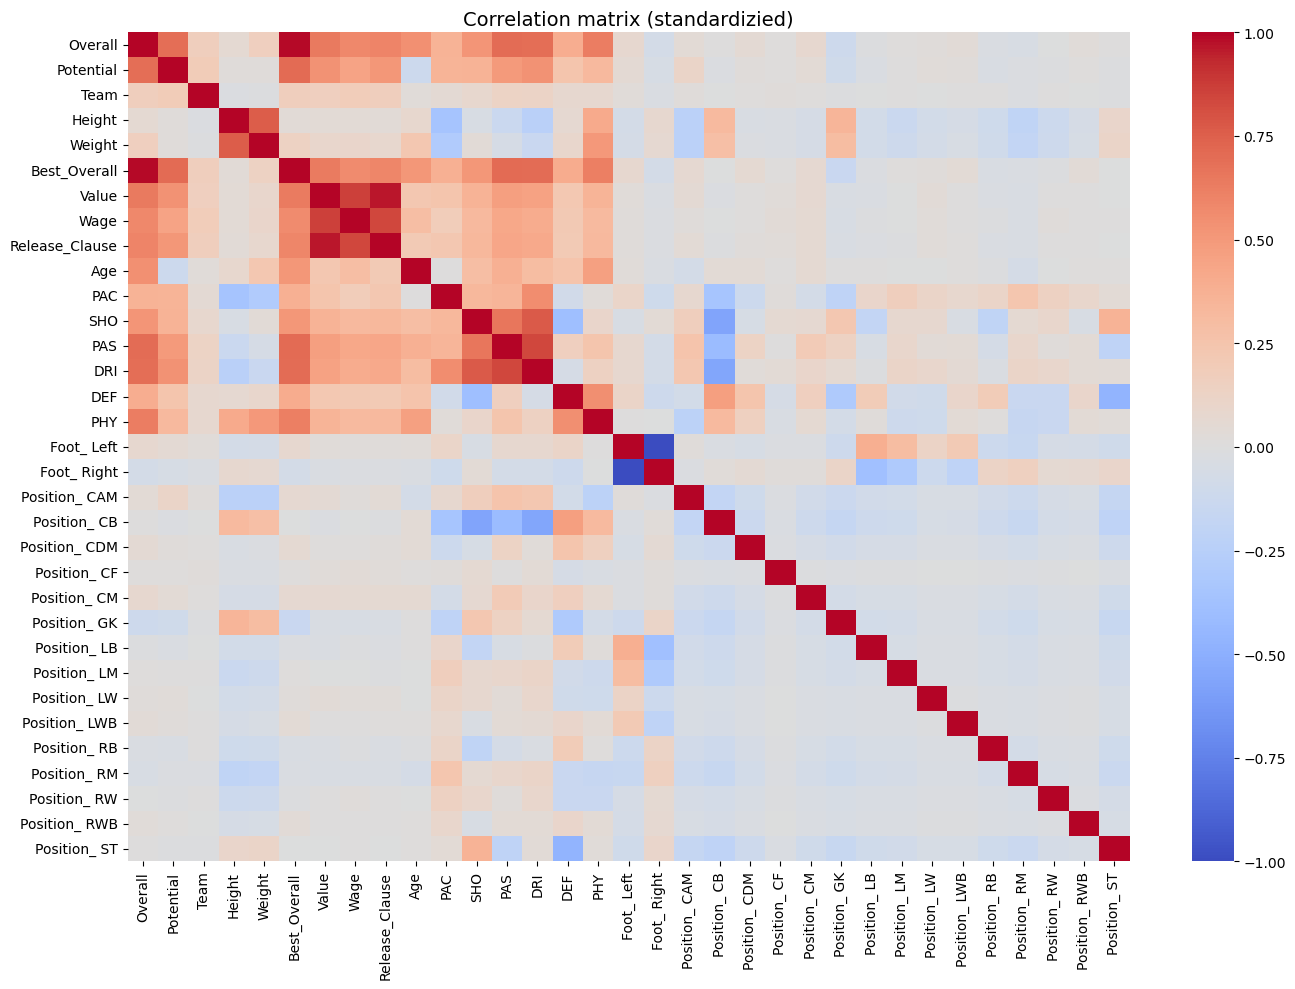

In [15]:

plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.title('Correlation matrix (standardizied)', fontsize=14)
plt.tight_layout()
plt.show()

Plot to see the difference between the potential and his value, the overall and his value and lastly the correlation between the wage and the valor

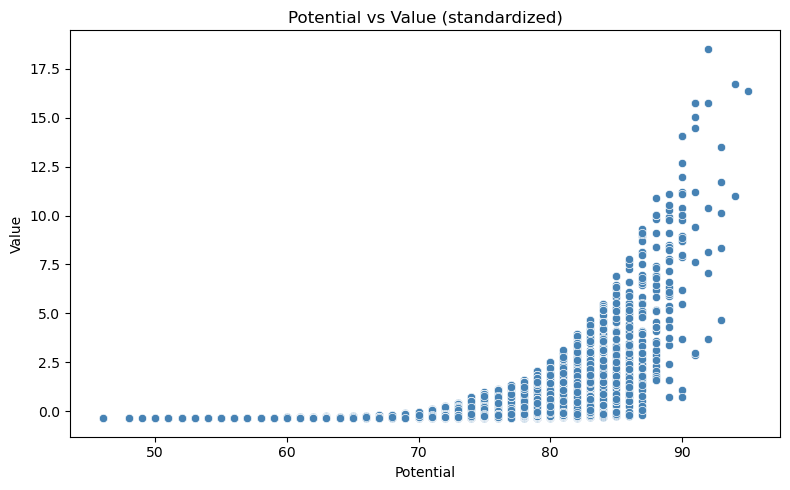

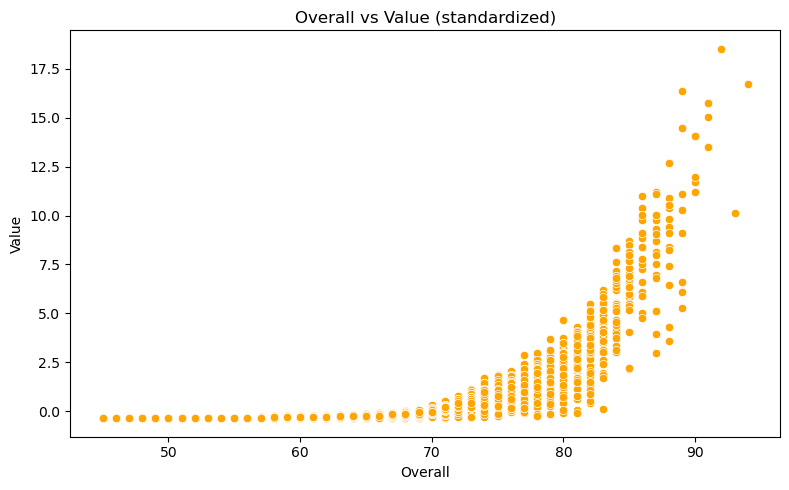

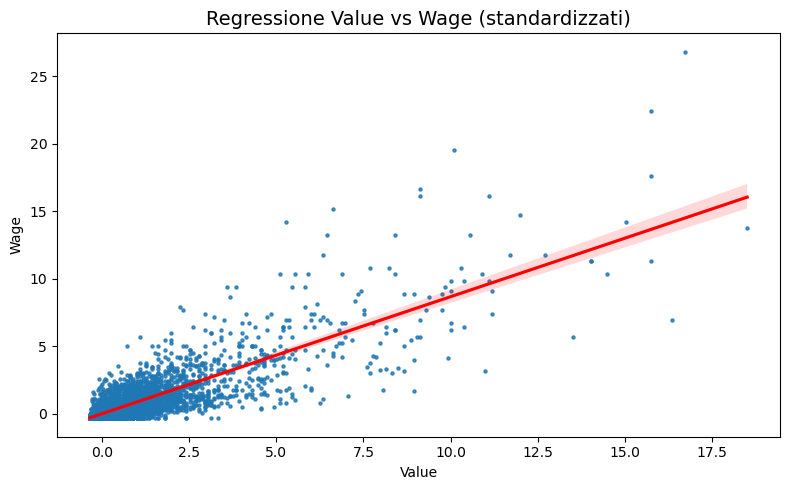

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Potential'], y=df['Value'], color='steelblue')
plt.title('Potential vs Value (standardized)')
plt.xlabel('Potential')
plt.ylabel('Value')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Overall'], y=df['Value'], color='orange')
plt.title('Overall vs Value (standardized)')
plt.xlabel('Overall')
plt.ylabel('Value')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(x=df['Value'], y=df['Wage'], scatter_kws={'s': 5}, line_kws={'color': 'red'})
plt.title('Regressione Value vs Wage (standardizzati)', fontsize=14)
plt.xlabel('Value')
plt.ylabel('Wage')
plt.tight_layout()
plt.show()




2 **Train and test regressor with the multiple output regressor to combine Value and Wage**

Split:

In [19]:
X = df.drop(['Value', 'Wage'], axis=1)
y = df[['Value', 'Wage']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Dictionary for model

- **NB**: for each model we use some estimator to use it then on grid search (as in lab4)
- **NB**: linear regression doesn't have parameter

In [21]:
model_params = {
    'Decision Tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'param_grid': {
            'estimator__max_depth': [None, 5, 10],
            'estimator__min_samples_split': [2, 4, 6]
        }
    },
    'Ridge Regression': {
        'model': Ridge(),
        'param_grid': {
            'estimator__alpha': [0.1, 1.0, 5.0]
        }
    },
    'SVR (RBF Kernel)': {
        'model': SVR(kernel='rbf'),
        'param_grid': {
            'estimator__C': [1, 10, 100],  
            'estimator__epsilon': [0.01, 0.1, 0.2] 
        }
    },
    'Linear Regression': {
        'model': LinearRegression(),
        'param_grid': {} 
    }
}

To save the models I create two dictionary, one for the trained model optimized, one for the prediction of the model

In [23]:
trained_models = {}
predictions_multioutput = {}

Train:

In [25]:
r2_scores_default = {}
for name, cfg in model_params.items():
    base_model = cfg['model']
    wrapped_model = MultiOutputRegressor(base_model)

    if cfg['param_grid']:
        estimator = GridSearchCV(wrapped_model, cfg['param_grid'], cv=3, scoring='r2', n_jobs=-1)
        estimator.fit(X_train, y_train)
        best_model = estimator.best_estimator_

    else: 
        wrapped_model.fit(X_train, y_train)
        best_model = wrapped_model
    y_pred_best = best_model.predict(X_test)

    default_model = MultiOutputRegressor(base_model.__class__()) 
    default_model.fit(X_train, y_train)
    y_pred_default = default_model.predict(X_test)
    # Save default model R² score
    score_default = r2_score(y_test, y_pred_default, multioutput='uniform_average')
    r2_scores_default[name] = score_default
    
    trained_models[name] = best_model
    predictions_multioutput[name] = best_model.predict(X_test)
print(r2_scores_default)

{'Decision Tree': 0.8762056889102512, 'Ridge Regression': 0.8519211777024618, 'SVR (RBF Kernel)': 0.7271387164287404, 'Linear Regression': 0.85245718992002}


3. **Train and test the regressors: multi-task lasso and multi-task elastic-net**

Dictionary for multitask models

In [26]:
multitask_models = {
    "MultiTaskLasso": {
        "model": MultiTaskLasso(max_iter=10000),
        "params": {
            "alpha": [0.01, 0.1, 1.0, 10.0]
        }
    },
    "MultiTaskElasticNet": {
        "model": MultiTaskElasticNet(max_iter=10000),
        "params": {
            "alpha": [0.01, 0.1, 1.0, 10.0],
            "l1_ratio": [0.1, 0.5, 0.9]
        }
    }
}

As before we create two dictionary to save the results

In [27]:
multitask_trained = {}
multitask_predictions = {}

Train:

In [28]:

for name, cfg in multitask_models.items():
    estimator = GridSearchCV(cfg["model"], cfg["params"], cv=3, scoring='r2', n_jobs=-1)
    estimator.fit(X_train, y_train)

    best_model = estimator.best_estimator_
    y_pred = best_model.predict(X_test)

    score_default = r2_score(y_test, y_pred_default, multioutput='uniform_average')
    r2_scores_default[name] = score_default

    multitask_trained[name] = best_model
    multitask_predictions[name] = y_pred


5. **R2 score computation**

Start to compute the r2 scores for both the point 2 and 3 models

In [29]:
r2_scores = {}

for name, y_pred in predictions_multioutput.items():
    score = r2_score(y_test, y_pred, multioutput='uniform_average')
    r2_scores[name] = score

for name, y_pred in multitask_predictions.items():
    score = r2_score(y_test, y_pred, multioutput='uniform_average')
    r2_scores[name] = score

Show of the r2 difference

{'Decision Tree': 0.9139082012347179, 'SVR (RBF Kernel)': 0.8967433287697513, 'Linear Regression': 0.85245718992002, 'Ridge Regression': 0.851910770477155, 'MultiTaskElasticNet': 0.8510581119826905, 'MultiTaskLasso': 0.8503133717374778}
{'Decision Tree': 0.8762056889102512, 'SVR (RBF Kernel)': 0.7271387164287404, 'Linear Regression': 0.85245718992002, 'Ridge Regression': 0.8519211777024618, 'MultiTaskElasticNet': 0.85245718992002, 'MultiTaskLasso': 0.85245718992002}
['Decision Tree', 'SVR (RBF Kernel)', 'Linear Regression', 'Ridge Regression', 'MultiTaskElasticNet', 'MultiTaskLasso']


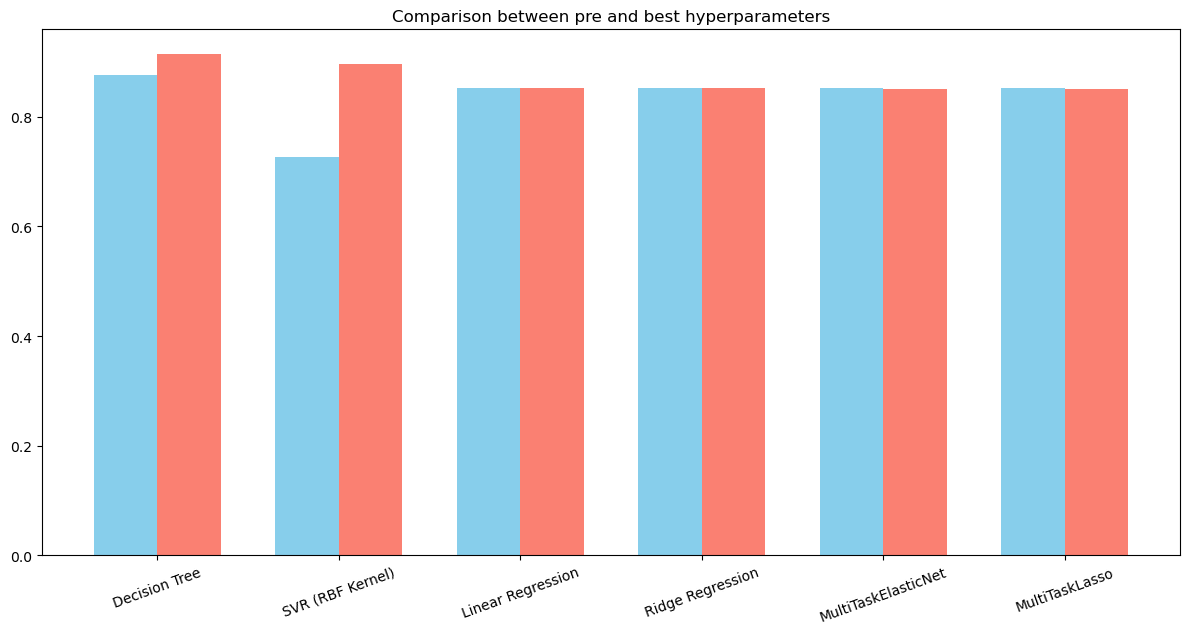

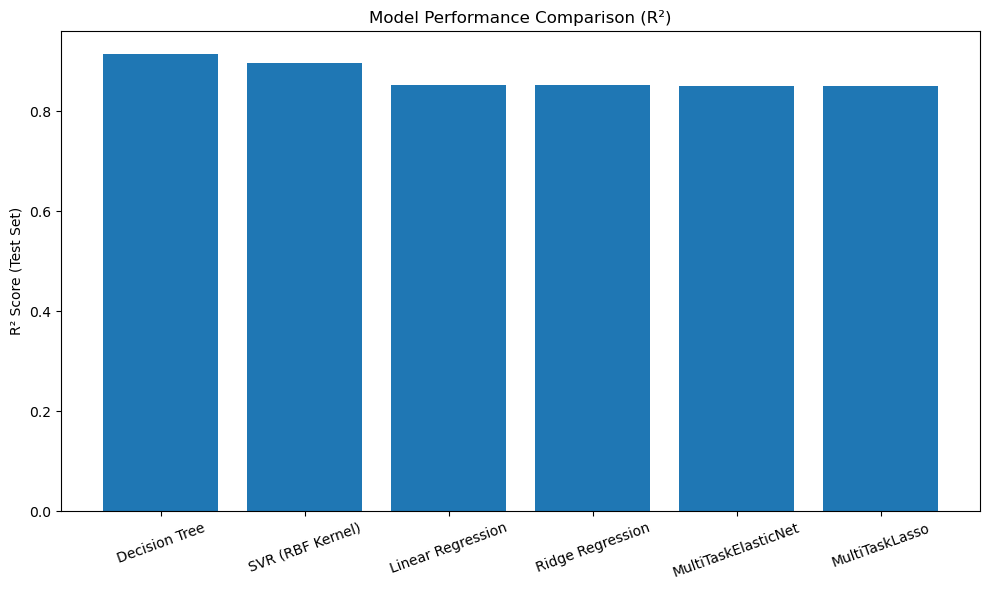

In [30]:
sorted_r2 = dict(sorted(r2_scores.items(), key=lambda item: item[1], reverse=True))
sorted_r2_default = {model: r2_scores_default[model] for model in sorted_r2.keys()}

print(sorted_r2)
print(sorted_r2_default)

models_sorted = list(sorted_r2.keys())

print(models_sorted)

default_scores_sorted = [r2_scores_default.get(m, np.nan) for m in models_sorted]
tuned_scores_sorted = [sorted_r2[m] for m in models_sorted]

x = np.arange(len(models_sorted))
width = 0.35

plt.figure(figsize=(12, 6))
plt.title("Comparison between pre and best hyperparameters")
plt.bar(x - width/2, default_scores_sorted, width, label='Default Hyperparameters', color='skyblue')
plt.bar(x + width/2, tuned_scores_sorted, width, label='Tuned Hyperparameters', color='salmon')
plt.tight_layout()
plt.xticks(ticks=x, labels=models_sorted, rotation=20)


plt.figure(figsize=(10, 6))
plt.bar(sorted_r2.keys(), sorted_r2.values())
plt.xticks(rotation=20)
plt.ylabel("R² Score (Test Set)")
plt.title("Model Performance Comparison (R²)")
plt.tight_layout()
plt.show()

To see which hiperparameter are the best:

In [31]:
print("=== MultiOutputRegressor models ===")
for name, model in trained_models.items():
    if hasattr(model, 'estimators_') and len(model.estimators_) > 0:
        print(f"{name}:")
        print(model.estimators_[0].get_params())

print("\n=== MultiTask models ===")
for name, model in multitask_trained.items():
    print(f"{name}:")
    print(model.get_params())

=== MultiOutputRegressor models ===
Decision Tree:
{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 4, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Ridge Regression:
{'alpha': 5.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
SVR (RBF Kernel):
{'C': 100, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Linear Regression:
{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

=== MultiTask models ===
MultiTaskLasso:
{'alpha': 0.01, 'copy_X': True, 'fit_intercept': True, 'max_iter': 10000, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
MultiTaskElasticN